# 3 · Training from scratch (and from the released weights)

The released results come from `configs/defect_aware_mae.json` (1,600 epochs, about 50 minutes on an RTX A4000)
and `configs/simclr.json` (800 epochs, about 90 minutes). This notebook

1. shows the exact commands and settings,
2. runs a short demonstration of the same training code so the loop can be inspected end to end,
3. shows how to continue training from the released weights,
4. compares against the stored loss curves of the full runs.

Set `DEMO = False` to launch the full training from here instead of the short demonstration.

In [1]:
import json, os, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)                                   # all paths below are relative to the repository root
from defect_aware_mae import data, evaluate, hub, report
from defect_aware_mae.data import CLASSES, load_split
from defect_aware_mae.models import embed, load_encoder
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 220)
print("repo:", ROOT.name, "| device:", DEVICE, "| torch", torch.__version__)
from defect_aware_mae import train
DEMO = True

repo: defect-aware-MAE | device: cuda | torch 2.9.1+cu128


## Settings of the released models

In [2]:
cfg = {n: json.load(open(f"configs/{n}.json")) for n in ("defect_aware_mae", "simclr", "mae_pixel_baseline")}
pd.DataFrame(cfg).fillna("-")

,defect_aware_mae,simclr,mae_pixel_baseline
method,mae,simclr,mae
target,hog,-,pix
masking,energy,-,random
beta,1.0,-,-
mask,0.75,-,0.75
strong,1,-,0
dec_depth,2,-,4
epochs,1600,800,800
bs,64,64,64
lr,0.00015,0.00015,0.00015


## Exact reproduction commands

```bash
python scripts/prepare_data.py --archive /path/to/NEU-DET.zip

# Defect-aware MAE, seeds 0-4
for s in 0 1 2 3 4; do
  python scripts/train.py --config configs/defect_aware_mae.json --seed $s --tag damae_s$s
  python scripts/evaluate.py runs/damae_s$s/ckpt.pth --out runs/damae_s$s/eval.json
done

# SimCLR baseline, seeds 0-4
for s in 0 1 2 3 4; do
  python scripts/train.py --config configs/simclr.json --seed $s --tag simclr_s$s
  python scripts/evaluate.py runs/simclr_s$s/ckpt.pth --out runs/simclr_s$s/eval.json
done
```

The same seed gives identical results on the same GPU model. Across GPU models, results differ slightly (for the
MAE, seed 0 gave 98.33% on two different RTX A4000 machines; SimCLR seed 0 gave 99.17% on an RTX 4070S and 98.33% on
an RTX A4000).

## Demonstration run

Same code path as the full run, shortened to a few epochs on a 256-image subset so it finishes in about a minute.
The numbers it produces are **not** results; it only shows that training runs and the loss decreases.

In [3]:
args = ["--config", "configs/defect_aware_mae.json", "--seed", "0"]
args += ["--tag", "demo_damae", "--epochs", "6", "--n", "256"] if DEMO else ["--tag", "damae_s0"]
out, hist = train.train(train.parse_args(args), log=lambda s: print(s[:110]))
print(os.listdir(out))

{"rec": 0.8745959177613258, "ep": 1, "min": 0.23, "lr": 0.00015}


{"rec": 0.3955863043665886, "ep": 2, "min": 0.44, "lr": 0.00013567627457812106}


{"rec": 0.37882160395383835, "ep": 3, "min": 0.65, "lr": 9.817627457812105e-05}


{"rec": 0.3669872507452965, "ep": 4, "min": 0.86, "lr": 5.182372542187895e-05}


{"rec": 0.36365704238414764, "ep": 5, "min": 1.08, "lr": 1.4323725421878949e-05}


{"rec": 0.3630254417657852, "ep": 6, "min": 1.29, "lr": 0.0}


done runs/demo_damae
['history.json', 'ckpt.pth', 'args.json']


## Continuing from the released weights

`--init_from` loads the encoder (and the decoder when shapes match) before training. Here: a few more epochs at a
small learning rate on the same subset. With the released weights the reconstruction loss starts near the
converged value of the full run (about 0.27 on this subset, 0.24 at the end of the full run) instead of near 0.9.

In [4]:
path, _ = hub.download("defect_aware_mae")
args = ["--config", "configs/defect_aware_mae.json", "--init_from", path, "--lr", "2e-5", "--seed", "0",
        "--tag", "demo_from_released", "--epochs", "3" if DEMO else "100"] + (["--n", "256"] if DEMO else [])
out2, hist2 = train.train(train.parse_args(args), log=lambda s: print(s[:110]))

{"rec": 0.2712460234761238, "ep": 1, "min": 0.21, "lr": 2e-05}


{"rec": 0.27272452414035797, "ep": 2, "min": 0.43, "lr": 1e-05}


{"rec": 0.27548200637102127, "ep": 3, "min": 0.64, "lr": 0.0}


done runs/demo_from_released


## Loss curves of the full runs (stored)

Blue: the five full 1,600-epoch runs behind the reported numbers. The demonstration runs above are overlaid.

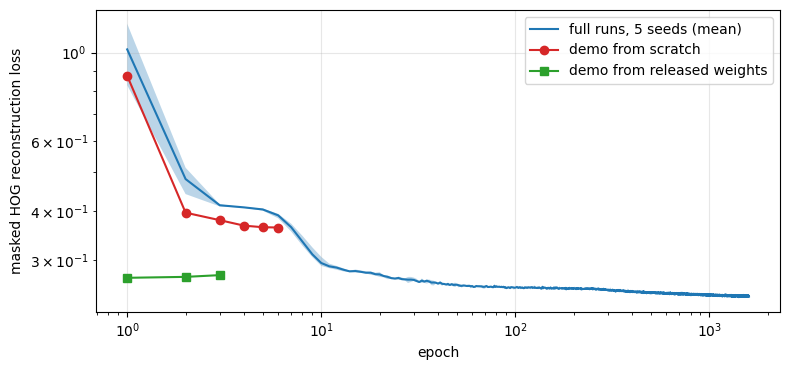

In [5]:
G = json.load(open("configs/groups.json")); tags = G[list(G)[0]]["tags"]
H = np.array([[e["rec"] for e in json.load(open(f"results/runs/{t}/history.json"))] for t in tags]); x = np.arange(1, H.shape[1] + 1)
plt.figure(figsize=(8, 3.8)); plt.plot(x, H.mean(0), label="full runs, 5 seeds (mean)"); plt.fill_between(x, H.min(0), H.max(0), alpha=.3)
plt.plot(range(1, len(hist) + 1), [e["rec"] for e in hist], "o-", c="tab:red", label="demo from scratch")
plt.plot(range(1, len(hist2) + 1), [e["rec"] for e in hist2], "s-", c="tab:green", label="demo from released weights")
plt.xscale("log"); plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("masked HOG reconstruction loss"); plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

## Evaluating a trained checkpoint

```bash
python scripts/evaluate.py runs/damae_s0/ckpt.pth --out runs/damae_s0/eval.json   # all readouts, full protocol
python scripts/gradcam.py  runs/damae_s0/ckpt.pth damae_s0 --mode mid             # Grad-CAM / Grad-CAM++
```

Expected for seed 0 on an RTX A4000 (`mid` readout): accuracy 98.33%, NMI 0.963, silhouette 0.827.